In [1]:
# Libraries
import pandas as pd
import numpy as np
import pyreadstat
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse
from stepmix.stepmix import StepMix
from scipy.stats import chi2_contingency
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

In [ ]:
# Data
df, meta = pyreadstat.read_sav("Data/NFCS 2024 Investor Data SPSS.sav")
print(df.head())  
print(df.shape)
print(df.columns.tolist()) 

         NFCSID   A1   A2   A3  B2_1  B2_2  B2_3  B2_4  B2_5  B2_7  ...   G11  \
0  2.024010e+09  1.0  1.0  1.0   2.0   2.0   1.0   2.0   2.0   1.0  ...   1.0   
1  2.024010e+09  1.0  1.0  1.0   1.0   2.0   1.0   2.0   2.0   2.0  ...  98.0   
2  2.024010e+09  1.0  2.0  1.0   1.0   2.0   2.0   2.0   2.0   2.0  ...   2.0   
3  2.024010e+09  1.0  1.0  1.0   1.0   2.0   2.0   2.0   2.0   2.0  ...   1.0   
4  2.024010e+09  1.0  1.0  1.0   1.0   2.0   1.0   2.0   2.0   2.0  ...   3.0   

   G12  G13   G23      WGT1  S_Gender2  S_Age  S_Ethnicity  S_Education  \
0  3.0  4.0   3.0  0.615651        2.0    3.0          1.0          2.0   
1  2.0  3.0  98.0  0.615651        2.0    3.0          2.0          2.0   
2  1.0  2.0   1.0  0.885309        2.0    2.0          1.0          2.0   
3  3.0  4.0   1.0  0.615651        1.0    3.0          1.0          2.0   
4  3.0  4.0  98.0  0.615651        1.0    3.0          1.0          2.0   

   S_Income  
0       2.0  
1       1.0  
2       1.0  
3     

In [3]:
# 1.1 Variables
risk_variables = ["B10", "B40"]
investment_variables = ["B30_2024", "B3"]
knowledge_variables = ["G4", "G5", "G6", "G7", "G21", "G8", "G44", "G22", "G11", "G12", "G13", "G23"]
study_data = df[risk_variables + investment_variables + knowledge_variables].copy()
print(study_data)

      B10  B40  B30_2024    B3   G4   G5    G6    G7   G21    G8  G44   G22  \
0     2.0  6.0       6.0   1.0  1.0  4.0   2.0   1.0   1.0   5.0  3.0  98.0   
1     3.0  6.0       5.0   4.0  1.0  2.0   2.0   1.0   1.0  98.0  3.0  98.0   
2     2.0  5.0       3.0   2.0  4.0  2.0   2.0   1.0   1.0   1.0  3.0   2.0   
3     3.0  5.0       6.0   3.0  1.0  2.0   2.0   1.0   2.0   1.0  3.0   1.0   
4     3.0  1.0       6.0   2.0  1.0  2.0   3.0   2.0   2.0   1.0  3.0   2.0   
...   ...  ...       ...   ...  ...  ...   ...   ...   ...   ...  ...   ...   
2856  1.0  7.0       3.0   3.0  1.0  2.0   2.0   1.0   1.0   1.0  3.0   1.0   
2857  3.0  7.0       6.0   4.0  1.0  4.0  98.0  98.0  98.0   5.0  3.0   3.0   
2858  3.0  1.0       6.0  98.0  1.0  2.0  98.0  98.0   2.0  98.0  3.0  98.0   
2859  3.0  7.0       1.0   1.0  1.0  2.0  98.0   1.0   2.0   4.0  3.0  98.0   
2860  2.0  3.0       6.0   4.0  1.0  2.0   2.0   1.0   2.0   1.0  3.0   2.0   

       G11   G12   G13   G23  
0      1.0   3.0   4

In [5]:
# 1.2 Missing values
missing_summary = pd.DataFrame({
    "Missing (NaN)": study_data.isna().sum(),
    "Don't know (98)": study_data.eq(98).sum(),
    "Prefer not to say (99)": study_data.eq(99).sum()
})
missing_summary["Total"] = missing_summary.sum(axis=1)
print(missing_summary)

          Missing (NaN)  Don't know (98)  Prefer not to say (99)  Total
B10                   0               37                       8     45
B40                   0               25                       5     30
B30_2024              0               38                       5     43
B3                    0              243                      22    265
G4                    0              143                      15    158
G5                    0              541                      20    561
G6                    0              670                      19    689
G7                    0              302                      14    316
G21                   0              296                      15    311
G8                    0              668                       7    675
G44                   0              293                      15    308
G22                   0             1180                      16   1196
G11                   0              880                      14

In [14]:
# 1.3 New Variable (knowledge_score)
answer_key = {
    "G4": 1, "G5": 2, "G6": 2, "G7": 1, "G21": 2, "G8": 1, 
    "G44": 3, "G22": 2, "G11": 3, "G12": 0, "G13": 4, "G23": 2
}
correct = pd.DataFrame(index=study_data.index)
for col, answer in answer_key.items():
    correct[col] = (study_data[col].eq(answer)).astype(int)
study_data["knowledge_score"] = correct.sum(axis=1) / len(answer_key)
print(study_data["knowledge_score"].head(10))

0    0.416667
1    0.416667
2    0.500000
3    0.666667
4    0.666667
5    0.583333
6    0.750000
7    0.500000
8    0.500000
9    0.250000
Name: knowledge_score, dtype: float64


In [15]:
# 1.4 Clean and reverse-code investment indicators
investment_indicators = ["B10", "B40", "B30_2024", "B3"]
study_data[investment_indicators] = study_data[investment_indicators].replace(
    [98, 99], np.nan
)
study_data["B10_reversed"] = 5 - study_data["B10"]
print(
    study_data[["B10", "B10_reversed"]]
    .drop_duplicates()
    .sort_values("B10")
)

    B10  B10_reversed
9   1.0           4.0
0   2.0           3.0
1   3.0           2.0
26  4.0           1.0
38  NaN           NaN


In [16]:
# 1.5 Final LCA indicators
lca_variables = ["B10_reversed", "B40", "B30_2024", "B3", "knowledge_score"]
lca_data = study_data[lca_variables].copy()
print(lca_data.head())

   B10_reversed  B40  B30_2024   B3  knowledge_score
0           3.0  6.0       6.0  1.0         0.416667
1           2.0  6.0       5.0  4.0         0.416667
2           3.0  5.0       3.0  2.0         0.500000
3           2.0  5.0       6.0  3.0         0.666667
4           2.0  1.0       6.0  2.0         0.666667


In [17]:
# 1.6 Descriptive statistics
descriptives = lca_data.describe().T.rename(columns={
    "count": "N", "mean": "Mean", "std": "SD", "min": "Minimum", 
    "25%": "Q1", "50%": "Median", "75%": "Q3", "max": "Maximum"
})
print(descriptives.round(3))

                      N   Mean     SD  Minimum     Q1  Median     Q3  Maximum
B10_reversed     2816.0  2.315  0.750      1.0  2.000     2.0  3.000    4.000
B40              2831.0  3.253  1.844      1.0  2.000     3.0  5.000    7.000
B30_2024         2818.0  5.306  1.183      1.0  5.000     6.0  6.000    6.000
B3               2596.0  2.238  1.057      1.0  1.000     2.0  3.000    4.000
knowledge_score  2861.0  0.469  0.208      0.0  0.333     0.5  0.583    0.917


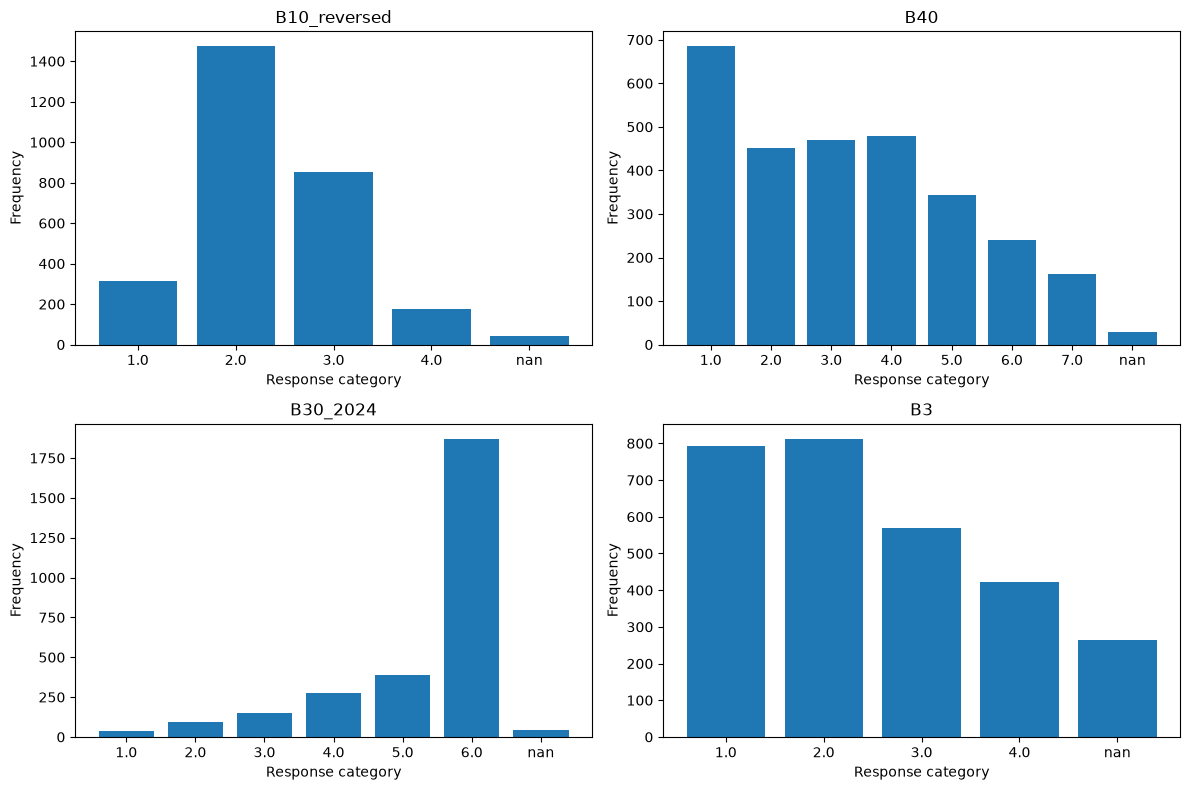

In [18]:
# 1.7 Frequency distributions and plots
ordinal_variables = ["B10_reversed", "B40", "B30_2024", "B3"]
frequency_tables = {}
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for v, ax in zip(ordinal_variables, axes.flatten()):
    counts = lca_data[v].value_counts(dropna=False).sort_index()
    frequency_tables[v] = pd.DataFrame({
        "Frequency": counts,
        "Percentage": counts / counts.sum() * 100
    })
    ax.bar(
        range(len(counts)),
        counts.values.astype(float)
    )
    ax.set_xticks(range(len(counts)))
    ax.set_xticklabels(counts.index.astype(str))
    ax.set(title=v, ylabel="Frequency", xlabel="Response category")
plt.tight_layout()
plt.show()


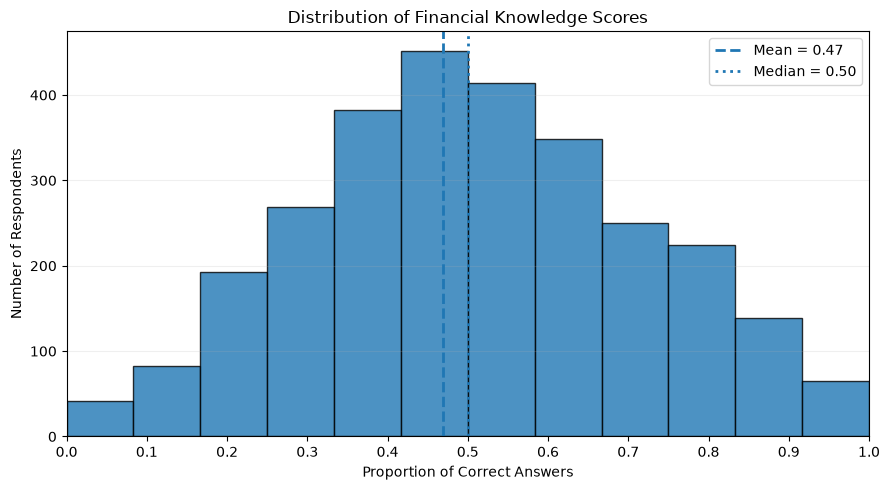

In [19]:
# 1.8 Knowledge score distribution
scores = study_data["knowledge_score"].dropna()
mean_score, median_score = scores.mean(), scores.median()
plt.figure(figsize=(9, 5))
plt.hist(scores, bins=np.linspace(0, 1, 13), edgecolor="black", alpha=0.8)
plt.axvline(mean_score, linestyle="--", linewidth=2,
            label=f"Mean = {mean_score:.2f}")
plt.axvline(median_score, linestyle=":", linewidth=2,
            label=f"Median = {median_score:.2f}")
plt.title("Distribution of Financial Knowledge Scores")
plt.xlabel("Proportion of Correct Answers")
plt.ylabel("Number of Respondents")
plt.xticks(np.linspace(0, 1, 11))
plt.xlim(0, 1)
plt.legend()
plt.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()



SPEARMAN CORRELATIONS
                  B10_reversed    B40  B30_2024     B3  knowledge_score
B10_reversed            1.000  0.505    -0.134  0.309            0.171
B40                     0.505  1.000    -0.311  0.204           -0.056
B30_2024               -0.134 -0.311     1.000 -0.062            0.236
B3                      0.309  0.204    -0.062  1.000            0.264
knowledge_score         0.171 -0.056     0.236  0.264            1.000

CORRELATION SAMPLE SIZES
                  B10_reversed   B40  B30_2024    B3  knowledge_score
B10_reversed             2816  2792      2780  2564             2816
B40                      2792  2831      2792  2570             2831
B30_2024                 2780  2792      2818  2565             2818
B3                       2564  2570      2565  2596             2596
knowledge_score          2816  2831      2818  2596             2861


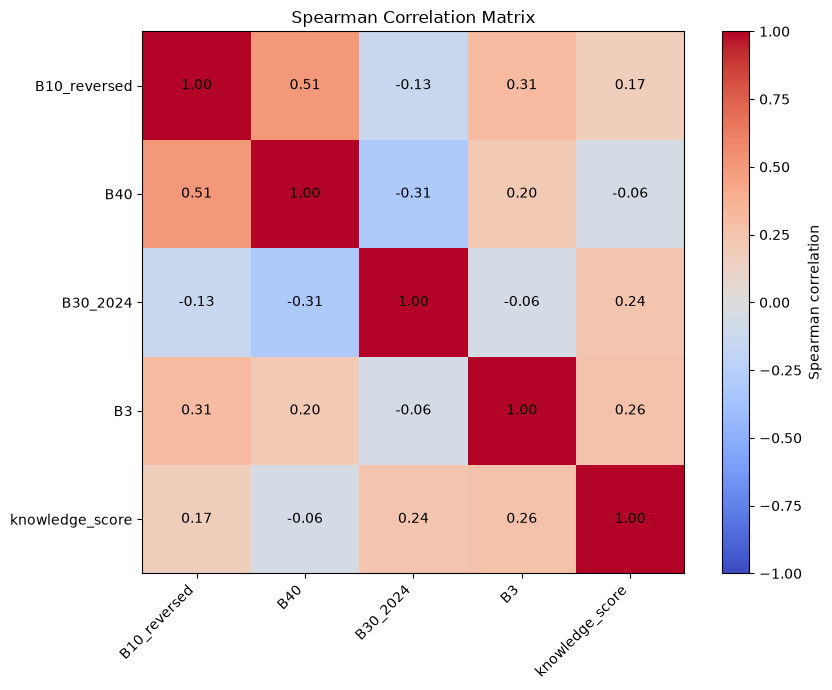

In [20]:
# 1.9 Spearman correlations and heatmap
correlation_matrix = lca_data.corr(method="spearman")
correlation_n = lca_data.notna().astype(int).T.dot(
    lca_data.notna().astype(int)
)
print("\nSPEARMAN CORRELATIONS\n", correlation_matrix.round(3))
print("\nCORRELATION SAMPLE SIZES\n", correlation_n)
fig, ax = plt.subplots(figsize=(9, 7))
image = ax.imshow(correlation_matrix, cmap="coolwarm", vmin=-1, vmax=1)
ax.set(xticks=range(len(lca_variables)), yticks=range(len(lca_variables)),
       xticklabels=lca_variables, yticklabels=lca_variables,
       title="Spearman Correlation Matrix")
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
for i in range(len(lca_variables)):
    for j in range(len(lca_variables)):
        ax.text(j, i, f"{correlation_matrix.iloc[i, j]:.2f}",
                ha="center", va="center")
fig.colorbar(image, ax=ax, label="Spearman correlation")
plt.tight_layout()
plt.show()

In [21]:
# 1.10 Prepare data for LCA
categorical_variables = ["B10_reversed", "B40", "B30_2024", "B3"]
continuous_variables = ["knowledge_score"]
lca_variables = categorical_variables + continuous_variables
lca_complete = lca_data[lca_variables].dropna().copy()
category_maps = {}
for v in categorical_variables:
    lca_complete[v] = lca_complete[v].astype("category")
    category_maps[v] = dict(enumerate(lca_complete[v].cat.categories))
    lca_complete[v] = lca_complete[v].cat.codes
X_lca = lca_complete.to_numpy(dtype=float)
n = len(X_lca)
print(lca_complete.head())
print("\nSample size:", n)
print("\nCategory mappings:", category_maps)

   B10_reversed  B40  B30_2024  B3  knowledge_score
0             2    5         5   0         0.416667
1             1    5         4   3         0.416667
2             2    4         2   1         0.500000
3             1    4         5   2         0.666667
4             1    0         5   1         0.666667

Sample size: 2519

Category mappings: {'B10_reversed': {0: 1.0, 1: 2.0, 2: 3.0, 3: 4.0}, 'B40': {0: 1.0, 1: 2.0, 2: 3.0, 3: 4.0, 4: 5.0, 5: 6.0, 6: 7.0}, 'B30_2024': {0: 1.0, 1: 2.0, 2: 3.0, 3: 4.0, 4: 5.0, 5: 6.0}, 'B3': {0: 1.0, 1: 2.0, 2: 3.0, 3: 4.0}}


In [22]:
# 1.11 Additional summary tables
sample_overview = pd.DataFrame({
    "Measure": ["Total observations", "Complete observations",
                "Excluded observations", "Percentage excluded"],
    "Value": [len(lca_data), len(lca_complete),
              len(lca_data) - len(lca_complete),
              lca_data.isna().any(axis=1).mean() * 100]
})
knowledge_summary = study_data["knowledge_score"].describe().to_frame(
    "Knowledge score"
)
knowledge_frequency = (
    study_data["knowledge_score"].value_counts().sort_index()
    .to_frame("Frequency")
)
knowledge_frequency["Percentage"] = (
    knowledge_frequency["Frequency"] /
    knowledge_frequency["Frequency"].sum() * 100
)

In [ ]:
# 1.12 Export data preparation results
with pd.ExcelWriter("Results/data_preparation_results.xlsx", engine="openpyxl") as writer:
    for name, data in {
        "Sample overview": sample_overview,
        "Missing values": missing_summary,
        "Descriptive statistics": descriptives,
        "Spearman correlations": correlation_matrix,
        "Knowledge summary": knowledge_summary,
        "Knowledge frequency": knowledge_frequency
    }.items():
        data.to_excel(writer, sheet_name=name)
    for v, table in frequency_tables.items():
        table.to_excel(writer, sheet_name=f"Freq_{v}")